In [2]:
import pandas as pd
import numpy as np

df = pd.read_csv("USA Covid Data.csv")
print(df.head())
print("\nDataset dimentions: ", df.shape)
print("\nDataset information: ")
df.info()
print("\nMissing values by column: ")
print(df.isnull().sum())
print("\nDescriptive statistics: ")
print(df.describe())

    USA State  Total Cases  Total Deaths  Total Recovered  Active Cases  \
0     Alabama      1659936         21138        1623935.0       14863.0   
1      Alaska       301513          1485         298902.0        1126.0   
2     Arizona      2508168         33749        2461333.0       13086.0   
3    Arkansas      1029976         13246        1012777.0        3953.0   
4  California     12393361        104634       12227662.0       61065.0   

   Tot Cases/ 1M pop  Deaths/ 1M pop  Total Tests  Tests/ 1M pop  Population  
0             338542            4311      9332317        1903317     4903185  
1             412159            2030      4790640        6548661      731545  
2             344589            4637     22489035        3089698     7278717  
3             341300            4389      8036831        2663139     3017804  
4             313659            2648    202799362        5132573    39512223  

Dataset dimentions:  (50, 10)

Dataset information: 
<class 'pandas.core.f

In [3]:
# STEP 2: DATA QUALITY CHECKS

# 1. Check for duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# 2. Check for duplicate state names
print("Duplicate state names:", df["USA State"].duplicated().sum())

# 3. Display the states with missing data
print("\nStates with missing values:")
print(df[df.isnull().any(axis=1)])

# 4. Check whether any numeric values are negative
numeric_df = df.select_dtypes(include="number")
print("\nNegative values by column:")
print((numeric_df < 0).sum())

# 5. Check whether reported cases exceed the population
print(
    "\nStates where total cases exceed population:",
    (df["Total Cases"] > df["Population"]).sum()
)

Duplicate rows: 0
Duplicate state names: 0

States with missing values:
         USA State  Total Cases  Total Deaths  Total Recovered  Active Cases  \
13         Indiana      2105286         26672              NaN           NaN   
28   New Hampshire       382013          3099              NaN           NaN   
32  North Carolina      3501404         29059              NaN           NaN   
37    Pennsylvania      3565499         51480              NaN           NaN   
40    South Dakota       282895          3231              NaN           NaN   

    Tot Cases/ 1M pop  Deaths/ 1M pop  Total Tests  Tests/ 1M pop  Population  
13             312718            3962     21512168        3195405     6732219  
28             280952            2279      4845153        3563370     1359711  
32             333846            2771     26656056        2541556    10488084  
37             278511            4021     30962562        2418574    12801989  
40             319779            3652      2331

In [4]:
# STEP 3: EXPLORE CASE AND DEATH RATES

# Top 10 states by reported cases per million people
top_cases = df.nlargest(10, "Tot Cases/ 1M pop")[
    ["USA State", "Tot Cases/ 1M pop", "Deaths/ 1M pop"]
]

print("TOP 10 STATES BY CASES PER MILLION:")
print(top_cases.to_string(index=False))


# Top 10 states by reported deaths per million people
top_deaths = df.nlargest(10, "Deaths/ 1M pop")[
    ["USA State", "Deaths/ 1M pop", "Tot Cases/ 1M pop"]
]

print("\nTOP 10 STATES BY DEATHS PER MILLION:")
print(top_deaths.to_string(index=False))

TOP 10 STATES BY CASES PER MILLION:
     USA State  Tot Cases/ 1M pop  Deaths/ 1M pop
  Rhode Island             418935            3933
        Alaska             412159            2030
      Kentucky             400111            4283
  North Dakota             385231            3298
     Tennessee             378983            4354
 West Virginia             367023            4569
      New York             366140            4015
       Florida             361221            4201
South Carolina             360838            3945
     Louisiana             357075            4122

TOP 10 STATES BY DEATHS PER MILLION:
    USA State  Deaths/ 1M pop  Tot Cases/ 1M pop
      Arizona            4637             344589
West Virginia            4569             367023
  Mississippi            4527             336144
   New Mexico            4405             325027
     Arkansas            4389             341300
    Tennessee            4354             378983
     Michigan            4334    

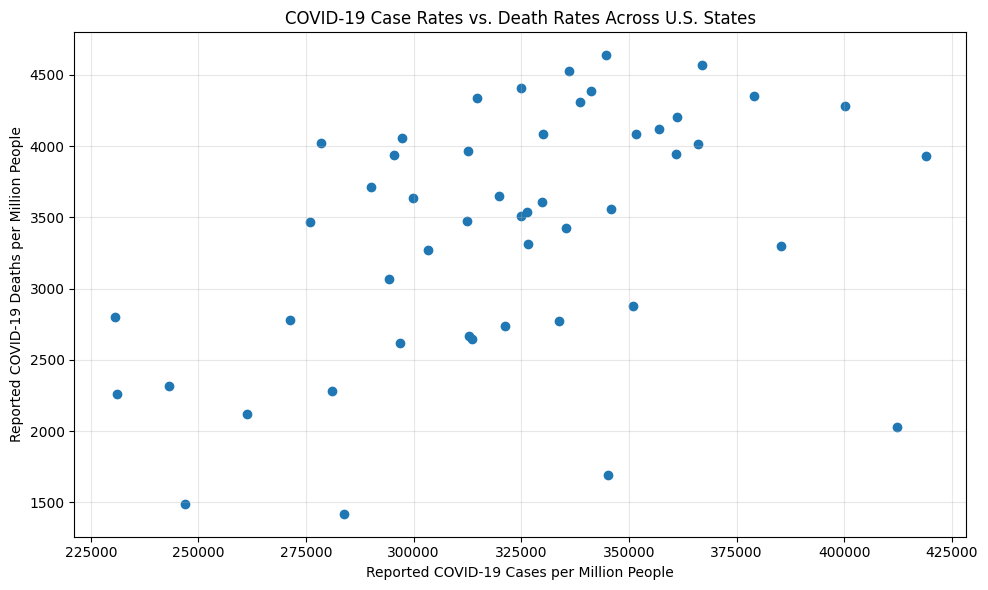

In [5]:
import matplotlib.pyplot as plt

# Scatter plot: reported case rates vs. reported death rates
plt.figure(figsize=(10, 6))

plt.scatter(
    df["Tot Cases/ 1M pop"],
    df["Deaths/ 1M pop"]
)

plt.xlabel("Reported COVID-19 Cases per Million People")
plt.ylabel("Reported COVID-19 Deaths per Million People")
plt.title("COVID-19 Case Rates vs. Death Rates Across U.S. States")

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [6]:
# STEP 5: CORRELATION ANALYSIS

# Select the variables we want to investigate
variables = [
    "Tot Cases/ 1M pop",
    "Deaths/ 1M pop",
    "Tests/ 1M pop"
]

# Calculate the Pearson correlation matrix
correlation_matrix = df[variables].corr(method="pearson")

print("PEARSON CORRELATION MATRIX:")
print(correlation_matrix.round(3))


# Examine individual relationships
pairs = [
    ("Tot Cases/ 1M pop", "Deaths/ 1M pop"),
    ("Tests/ 1M pop", "Tot Cases/ 1M pop"),
    ("Tests/ 1M pop", "Deaths/ 1M pop")
]

print("\nINDIVIDUAL CORRELATIONS:")

for x, y in pairs:
    correlation = df[x].corr(df[y])

    print(
        f"{x} vs. {y}: "
        f"correlation = {correlation:.3f}"
    )

PEARSON CORRELATION MATRIX:
                   Tot Cases/ 1M pop  Deaths/ 1M pop  Tests/ 1M pop
Tot Cases/ 1M pop              1.000           0.459          0.205
Deaths/ 1M pop                 0.459           1.000         -0.179
Tests/ 1M pop                  0.205          -0.179          1.000

INDIVIDUAL CORRELATIONS:
Tot Cases/ 1M pop vs. Deaths/ 1M pop: correlation = 0.459
Tests/ 1M pop vs. Tot Cases/ 1M pop: correlation = 0.205
Tests/ 1M pop vs. Deaths/ 1M pop: correlation = -0.179


                            OLS Regression Results                            
Dep. Variable:         Deaths/ 1M pop   R-squared:                       0.211
Model:                            OLS   Adj. R-squared:                  0.194
Method:                 Least Squares   F-statistic:                     12.83
Date:                Thu, 22 Oct 2026   Prob (F-statistic):           0.000794
Time:                        20:52:44   Log-Likelihood:                -402.07
No. Observations:                  50   AIC:                             808.1
Df Residuals:                      48   BIC:                             812.0
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
const               468.1895    826.74

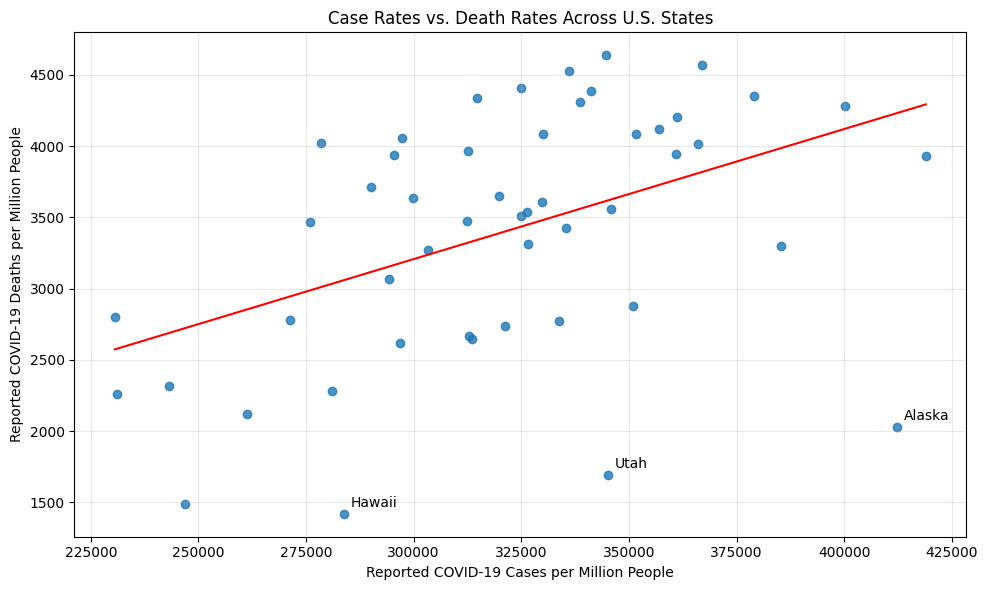

                            OLS Regression Results                            
Dep. Variable:         Deaths/ 1M pop   R-squared:                       0.289
Model:                            OLS   Adj. R-squared:                  0.259
Method:                 Least Squares   F-statistic:                     9.547
Date:                Thu, 22 Oct 2026   Prob (F-statistic):           0.000332
Time:                        20:52:45   Log-Likelihood:                -399.47
No. Observations:                  50   AIC:                             804.9
Df Residuals:                      47   BIC:                             810.7
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
const               642.6725    796.86

In [7]:
import statsmodels.api as sm
import matplotlib.pyplot as plt
import numpy as np

c, d, t = "Tot Cases/ 1M pop", "Deaths/ 1M pop", "Tests/ 1M pop"

# Simple regression
X = sm.add_constant(df[c])
model = sm.OLS(df[d], X).fit()
print(model.summary())

# Influence / outlier diagnostics
infl = model.get_influence()
df["stud_resid"] = infl.resid_studentized_external
df["cooks_d"] = infl.cooks_distance[0]
print(df.loc[df["stud_resid"].abs() > 2, ["USA State", c, d, "stud_resid", "cooks_d"]])

# Plot with regression line and labeled outliers
plt.figure(figsize=(10, 6))
plt.scatter(df[c], df[d], alpha=0.8)
xs = np.linspace(df[c].min(), df[c].max(), 100)
plt.plot(xs, model.params["const"] + model.params[c] * xs, color="red")
for _, row in df[df["stud_resid"].abs() > 2].iterrows():
    plt.annotate(row["USA State"], (row[c], row[d]), xytext=(5, 5), textcoords="offset points")
plt.xlabel("Reported COVID-19 Cases per Million People")
plt.ylabel("Reported COVID-19 Deaths per Million People")
plt.title("Case Rates vs. Death Rates Across U.S. States")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Multiple regression: add testing rate
model2 = sm.OLS(df[d], sm.add_constant(df[[c, t]])).fit()
print(model2.summary())

In [8]:
# Rescale: cases per 10,000 per million, tests per million (in millions)
df["cases_10k"] = df["Tot Cases/ 1M pop"] / 10000
df["tests_M"] = df["Tests/ 1M pop"] / 1e6

# 1. Rescaled model with robust (HC3) standard errors
m_rob = sm.OLS(df["Deaths/ 1M pop"], sm.add_constant(df[["cases_10k"]])).fit(cov_type="HC3")
print(m_rob.summary().tables[1])

# 2. Same model without Alaska, Utah, Hawaii
sub = df[~df["USA State"].isin(["Alaska", "Utah", "Hawaii"])]
m_sub = sm.OLS(sub["Deaths/ 1M pop"], sm.add_constant(sub[["cases_10k"]])).fit()
print("\nWithout Alaska, Utah, Hawaii:")
print(m_sub.summary().tables[1])
print("R-squared:", round(m_sub.rsquared, 3), "| n =", int(m_sub.nobs))

# 3. Two-predictor model, rescaled, robust SEs
m_two = sm.OLS(df["Deaths/ 1M pop"], sm.add_constant(df[["cases_10k", "tests_M"]])).fit(cov_type="HC3")
print("\nCases + tests (robust SEs):")
print(m_two.summary().tables[1])

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const        468.1895   1016.648      0.461      0.645   -1524.403    2460.782
cases_10k     91.2776     32.240      2.831      0.005      28.088     154.467

Without Alaska, Utah, Hawaii:
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       -173.1355    675.349     -0.256      0.799   -1533.357    1187.086
cases_10k    115.1536     20.930      5.502      0.000      72.999     157.309
R-squared: 0.402 | n = 47

Cases + tests (robust SEs):
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const        642.6725    953.219      0.674      0.500   -1225.602    2510.947
cases_10k    102.9138     27.388      3.758  

(187, 5) 0 missing | 0 duplicates
       doses_per_100  pct_vax  pct_full
count          187.0    187.0     187.0
mean           141.9     60.2      55.0
std             82.7     25.2      25.2
min              0.0      0.2       0.2
25%             70.5     42.0      34.5
50%            142.0     64.0      57.0
75%            207.5     81.5      76.0
max            379.0     99.0      99.0

Largest drop-off (one dose to fully vaccinated):
   country  pct_vax  pct_full  dropoff
 Venezuela     78.0      52.0     26.0
    Guinea     48.0      26.0     22.0
    Angola     47.0      26.0     21.0
  Kiribati     82.0      63.0     19.0
     Libya     34.0      18.0     16.0
     Egypt     54.0      40.0     14.0
    Guyana     63.0      49.0     14.0
     Tonga     88.0      74.0     14.0
    Uganda     43.0      29.0     14.0
Bangladesh     92.0      79.0     13.0

Highest % fully vaccinated:
       country  pct_full
        Brunei      99.0
         Macau      99.0
         Qatar      99.

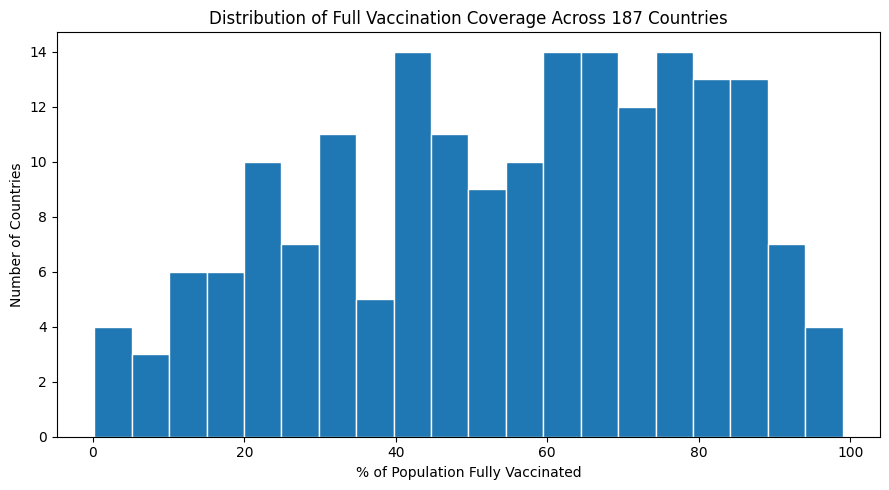

In [9]:
vax = pd.read_csv("Worldwide Vaccine Data.csv")   # use your uploaded filename
vax.columns = ["country", "doses_per_100", "total_doses", "pct_vax", "pct_full"]

print(vax.shape, vax.isnull().sum().sum(), "missing |", vax.duplicated().sum(), "duplicates")
print(vax[["doses_per_100", "pct_vax", "pct_full"]].describe().round(1))

# 1. Dropoff between at least one dose and fully vaccinated
vax["dropoff"] = vax["pct_vax"] - vax["pct_full"]
print("\nLargest drop-off (one dose to fully vaccinated):")
print(vax.nlargest(10, "dropoff")[["country", "pct_vax", "pct_full", "dropoff"]].to_string(index=False))

# 2. Highest and lowest full vaccination
print("\nHighest % fully vaccinated:")
print(vax.nlargest(10, "pct_full")[["country", "pct_full"]].to_string(index=False))
print("\nLowest % fully vaccinated:")
print(vax.nsmallest(10, "pct_full")[["country", "pct_full"]].to_string(index=False))

# 3. Correlation
from scipy import stats
print("\nDoses/100 vs % fully vaccinated:", stats.pearsonr(vax["doses_per_100"], vax["pct_full"]))

# 4. Histogram
plt.figure(figsize=(9, 5))
plt.hist(vax["pct_full"], bins=20, edgecolor="white")
plt.xlabel("% of Population Fully Vaccinated")
plt.ylabel("Number of Countries")
plt.title("Distribution of Full Vaccination Coverage Across 187 Countries")
plt.tight_layout()
plt.show()